In [68]:
import pandas as pd
import numpy as np
from sklearn . model_selection import train_test_split
from sklearn . preprocessing import StandardScaler
from sklearn . neighbors import KNeighborsClassifier
from sklearn . cluster import KMeans
from sklearn . metrics import (accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay)
import matplotlib . pyplot as plt
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec


In [69]:
df = pd . read_csv ("/kaggle/input/datasets/huhao05133/carseats/Carseats.csv")
df.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [70]:
df ["High"] = ( df ["Sales"] > 8). astype (int )

In [71]:
X = df . drop ( columns =[ "Sales" , "High" ])
y = df [ "High" ]
# Encodage des variables qualitatives
X = pd . get_dummies (X , drop_first = True )

In [72]:
X_train , X_test , y_train , y_test = train_test_split (
X , y , test_size =0.3 , random_state =0
)

In [73]:
scaler = StandardScaler ()
X_train_scaled = scaler . fit_transform ( X_train )
X_test_scaled = scaler . transform ( X_test )

In [74]:
model = KNeighborsClassifier ( n_neighbors =3)
model . fit ( X_train_scaled , y_train )

KNeighborsClassifier(n_neighbors=3)

In [75]:
y_pred = model . predict ( X_test_scaled )
print ( " Accuracy = " , accuracy_score ( y_test , y_pred ))

 Accuracy =  0.7666666666666667


# **2)**

In [76]:
X_cluster = df . drop ( columns =[ "Sales" , "High" ])
X_cluster = pd . get_dummies ( X_cluster , drop_first = True )
scaler = StandardScaler ()
X_cluster_scaled = scaler . fit_transform ( X_cluster )

In [77]:
kmeans = KMeans ( n_clusters =4 , random_state =0)
clusters = kmeans . fit_predict ( X_cluster_scaled )
df [ "Cluster" ] = clusters
df . head ()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US,High,Cluster
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes,1,1
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes,1,3
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes,1,0
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes,0,0
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No,0,2


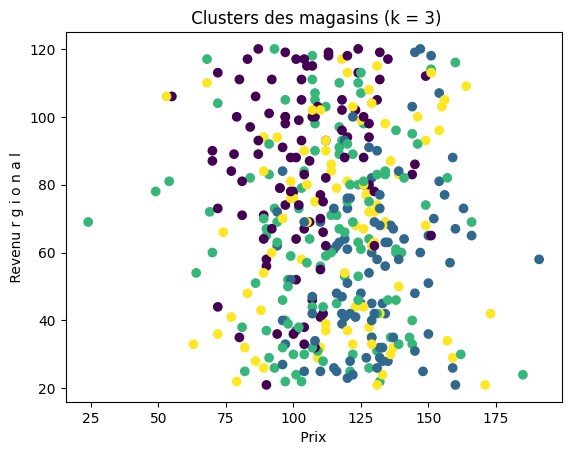

In [78]:
plt . scatter ( df [ "Price" ] , df [ "Income" ] , c = df ["Cluster"])
plt . xlabel ( " Prix " )
plt . ylabel ( " Revenu r g i o n a l " )
plt . title ( " Clusters des magasins (k = 3)" )
plt . show ()

# 3) Random Forest

In [79]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

In [80]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=0)
rf_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=0)

In [81]:
y_pred_rf = rf_model.predict(X_test_scaled)

acc_rf = accuracy_score(y_test, y_pred_rf)
print(f"\nRandom Forest Accuracy (100 trees) : {acc_rf:.4f}")


Random Forest Accuracy (100 trees) : 0.8000


In [82]:

tree_options = [10, 50, 100, 200, 500]

accuracy_list = []

best_accuracy = 0
best_trees = 0

for k in tree_options:

    model = RandomForestClassifier(
        n_estimators=k,
        random_state=0
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)

    accuracy_list.append(accuracy)

    print("Trees:", k, "| Accuracy:", round(accuracy, 4))

    if accuracy > best_accuracy:
        best_accuracy = accuracy
        best_trees = k

print("\nBest number of trees:", best_trees)
print("Best accuracy:", round(best_accuracy, 4))

Trees: 10 | Accuracy: 0.7667
Trees: 50 | Accuracy: 0.7667
Trees: 100 | Accuracy: 0.8
Trees: 200 | Accuracy: 0.7833
Trees: 500 | Accuracy: 0.7833

Best number of trees: 100
Best accuracy: 0.8


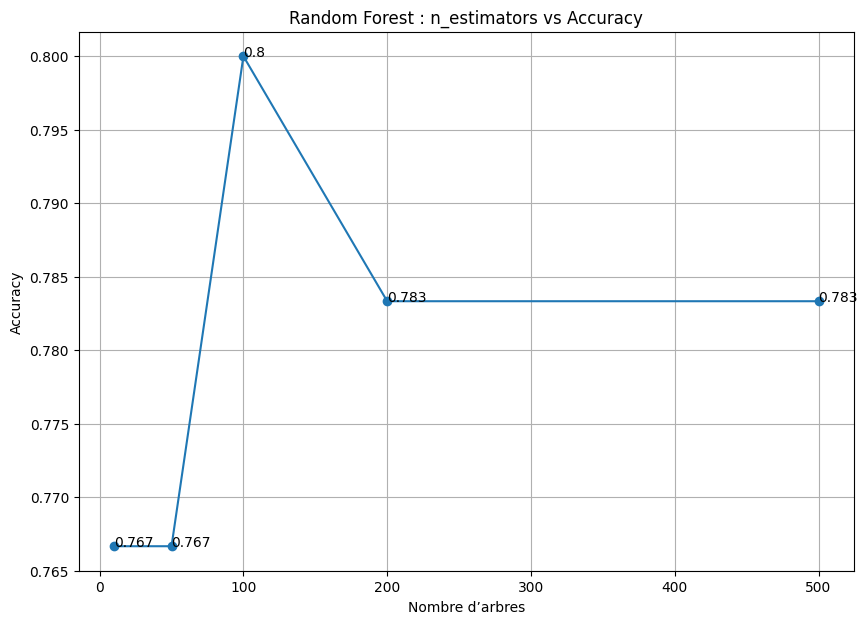

In [102]:
plt.figure(figsize=(10, 7))

plt.plot(
    tree_options,
    accuracy_list,
    marker="o"
)

plt.title("Random Forest : n_estimators vs Accuracy")
plt.xlabel("Nombre d’arbres")
plt.ylabel("Accuracy")

plt.grid(True)

for i in range(len(tree_options)):
    plt.text(
        tree_options[i],
        accuracy_list[i],
        round(accuracy_list[i], 3)
    )

plt.show()

In [84]:
cm_rf = confusion_matrix(y_test, y_pred_rf)
print("Confusion Matrix (RF):\n", cm_rf)

Confusion Matrix (RF):
 [[59  8]
 [16 37]]


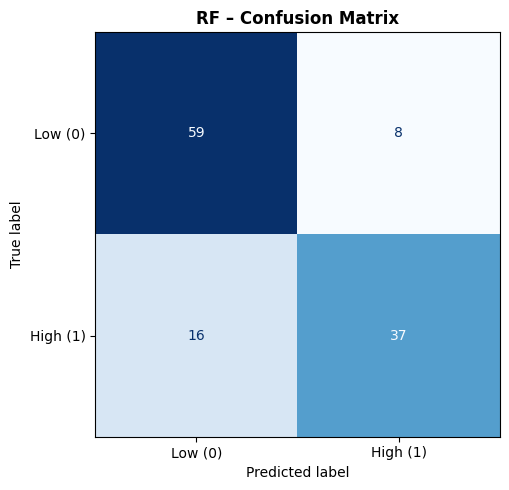

In [85]:
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Low (0)", "High (1)"]
)

disp_rf.plot(
    ax=ax,
    colorbar=False,
    cmap="Blues"
)

ax.set_title("RF – Confusion Matrix", fontweight="bold")

plt.tight_layout()
plt.show()

In [86]:
print("Classification Report (RF):")
print(classification_report(y_test, y_pred_rf, target_names=["Low (0)", "High (1)"]))


Classification Report (RF):
              precision    recall  f1-score   support

     Low (0)       0.79      0.88      0.83        67
    High (1)       0.82      0.70      0.76        53

    accuracy                           0.80       120
   macro avg       0.80      0.79      0.79       120
weighted avg       0.80      0.80      0.80       120



In [87]:
importances = rf_model.feature_importances_
feat_names  = X.columns
feat_imp_df = pd.DataFrame({"Feature": feat_names, "Importance": importances})
feat_imp_df = feat_imp_df.sort_values("Importance", ascending=False).reset_index(drop=True)

print("Top 10 Most Important Features (RF):")
print(feat_imp_df.head(10).to_string(index=False))

Top 10 Most Important Features (RF):
         Feature  Importance
           Price    0.242944
             Age    0.123964
       CompPrice    0.122586
          Income    0.113964
     Advertising    0.112167
      Population    0.082038
  ShelveLoc_Good    0.078846
       Education    0.059182
ShelveLoc_Medium    0.026011
          US_Yes    0.020936


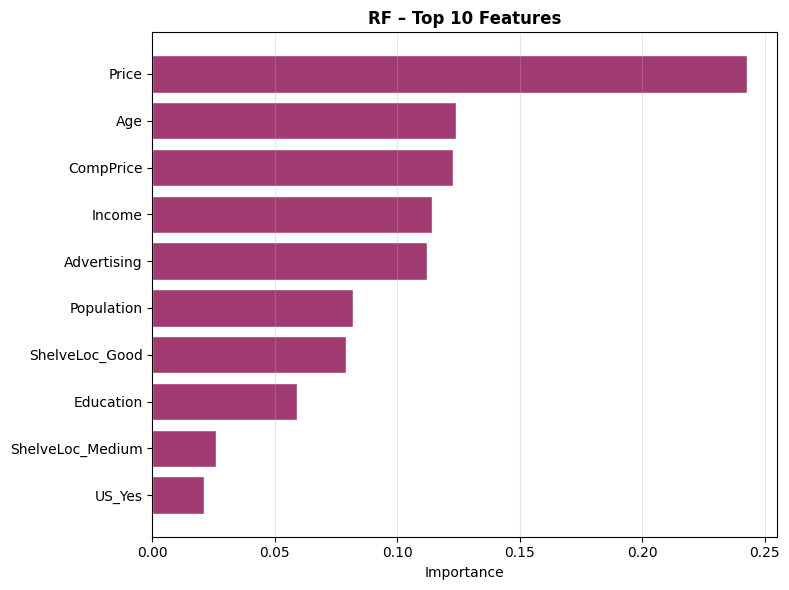

In [88]:
fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")

top10 = feat_imp_df.head(10)

ax.barh(
    top10["Feature"][::-1],
    top10["Importance"][::-1],
    color="#A23B72",
    edgecolor="white"
)

ax.set_title("RF – Top 10 Features", fontweight="bold")
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

# 4) SVM

In [89]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=0)
svm_model.fit(X_train_scaled, y_train)

y_pred_svm = svm_model.predict(X_test_scaled)

acc_svm = accuracy_score(y_test, y_pred_svm)
print(f"SVM Accuracy  (kernel=rbf, C=1) : {acc_svm:.4f}")


SVM Accuracy  (kernel=rbf, C=1) : 0.8417


In [90]:
kernels   = ["linear", "poly", "rbf", "sigmoid"]
acc_svm_k = []

for k in kernels:
    clf = SVC(kernel=k, C=1.0, gamma="scale", random_state=0)
    clf.fit(X_train_scaled, y_train)
    a = accuracy_score(y_test, clf.predict(X_test_scaled))
    acc_svm_k.append(a)
    print(f"  kernel = {k}  →  Accuracy = {a:.4f}")

best_kernel = kernels[acc_svm_k.index(max(acc_svm_k))]
print(f"Best kernel = '{best_kernel}'  (accuracy = {max(acc_svm_k):.4f})")

  kernel = linear  →  Accuracy = 0.8833
  kernel = poly  →  Accuracy = 0.8083
  kernel = rbf  →  Accuracy = 0.8417
  kernel = sigmoid  →  Accuracy = 0.8583
Best kernel = 'linear'  (accuracy = 0.8833)


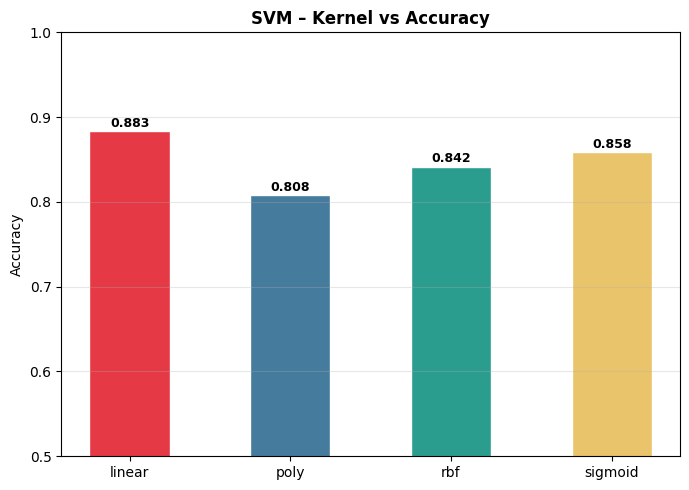

In [91]:
fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")

bar_colors = ["#E63946", "#457B9D", "#2A9D8F", "#E9C46A"]

bars = ax.bar(
    kernels,
    acc_svm_k,
    color=bar_colors,
    edgecolor="white",
    width=0.5
)

ax.set_title("SVM – Kernel vs Accuracy", fontweight="bold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 1.0)
ax.grid(axis="y", alpha=0.3)

for bar, acc in zip(bars, acc_svm_k):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        acc + 0.005,
        f"{acc:.3f}",
        ha="center",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

In [92]:
C_values  = [0.01, 0.1, 1, 10, 100]
acc_svm_C = []

print("\nTuning C parameter  (kernel=rbf):")
for c in C_values:
    clf = SVC(kernel="rbf", C=c, gamma="scale", random_state=0)
    clf.fit(X_train_scaled, y_train)
    a = accuracy_score(y_test, clf.predict(X_test_scaled))
    acc_svm_C.append(a)
    print(f"  C = {c}  →  Accuracy = {a:.4f}")

best_C = C_values[acc_svm_C.index(max(acc_svm_C))]
print(f"Best C = {best_C}  (accuracy = {max(acc_svm_C):.4f})")


Tuning C parameter  (kernel=rbf):
  C = 0.01  →  Accuracy = 0.5583
  C = 0.1  →  Accuracy = 0.5750
  C = 1  →  Accuracy = 0.8417
  C = 10  →  Accuracy = 0.8333
  C = 100  →  Accuracy = 0.8167
Best C = 1  (accuracy = 0.8417)


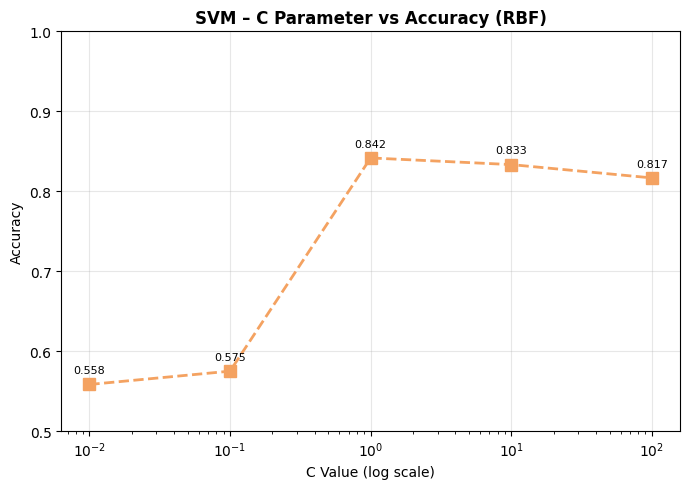

In [93]:
fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")

ax.semilogx(
    C_values,
    acc_svm_C,
    "s--",
    color="#F4A261",
    linewidth=2,
    markersize=8
)

ax.set_title("SVM – C Parameter vs Accuracy (RBF)", fontweight="bold")
ax.set_xlabel("C Value (log scale)")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 1.0)
ax.grid(True, alpha=0.3)

for x, y in zip(C_values, acc_svm_C):
    ax.annotate(
        f"{y:.3f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()

In [94]:
cm_svm = confusion_matrix(y_test, y_pred_svm)
print("Confusion Matrix (SVM):\n", cm_svm)


Confusion Matrix (SVM):
 [[60  7]
 [12 41]]


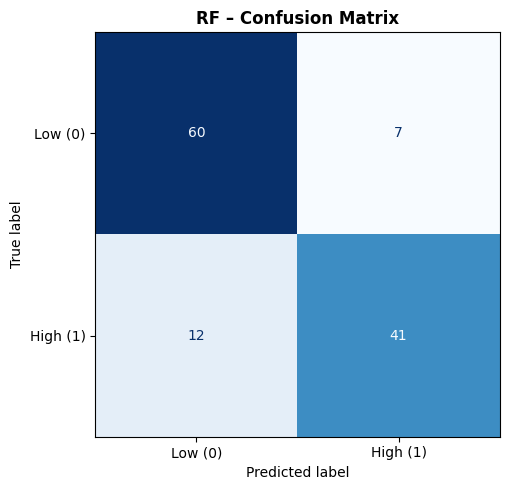

In [95]:
fig, ax = plt.subplots(figsize=(6, 5), facecolor="white")

disp_rf = ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Low (0)", "High (1)"]
)

disp_rf.plot(
    ax=ax,
    colorbar=False,
    cmap="Blues"
)

ax.set_title("RF – Confusion Matrix", fontweight="bold")

plt.tight_layout()
plt.show()

In [96]:
print("Classification Report (SVM):")
print(classification_report(y_test, y_pred_svm, target_names=["Low (0)", "High (1)"]))


Classification Report (SVM):
              precision    recall  f1-score   support

     Low (0)       0.83      0.90      0.86        67
    High (1)       0.85      0.77      0.81        53

    accuracy                           0.84       120
   macro avg       0.84      0.83      0.84       120
weighted avg       0.84      0.84      0.84       120



In [97]:
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(X_train_scaled, y_train)
acc_knn5 = accuracy_score(y_test, knn5.predict(X_test_scaled))

models_names = ["KNN (k=5)", "Random Forest", "SVM (rbf)"]
models_acc   = [acc_knn5,    acc_rf,          acc_svm   ]

print("\n  Model            |  Accuracy")
print("  " + "-"*34)
for name, acc in zip(models_names, models_acc):
    print(f"  {name}|  {acc:.4f}")

best_model = models_names[models_acc.index(max(models_acc))]
print(f"Best overall model : {best_model}  ({max(models_acc):.4f})")



  Model            |  Accuracy
  ----------------------------------
  KNN (k=5)|  0.7667
  Random Forest|  0.8000
  SVM (rbf)|  0.8417
Best overall model : SVM (rbf)  (0.8417)


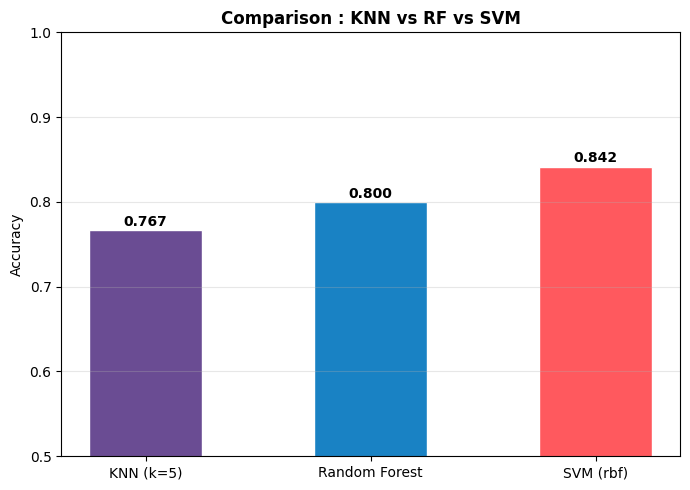

In [98]:
fig, ax = plt.subplots(figsize=(7, 5), facecolor="white")

bar_colors = ["#6A4C93", "#1982C4", "#FF595E"]

bars = ax.bar(
    models_names,
    models_acc,
    color=bar_colors,
    edgecolor="white",
    width=0.5
)

ax.set_title("Comparison : KNN vs RF vs SVM", fontweight="bold")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.5, 1.0)
ax.grid(axis="y", alpha=0.3)

for bar, acc in zip(bars, models_acc):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        acc + 0.005,
        f"{acc:.3f}",
        ha="center",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()